# Credit Card Default Prediction: Fairness and Explainability Analysis


## 1. Introduction
This project aims to explore fairness and interpretability in machine learning using a structured dataset.
We use a Random Forest Classifier and evaluate its ethical behavior using fairness metrics and SHAP explainability.

In [ ]:
!pip install - q interpret alibi dice-ml

In [ ]:
!pip install shap
!pip install lime

In [ ]:
# Importing libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report
import statsmodels.api as sm
from sklearn.ensemble import RandomForestClassifier
from interpret.glassbox import ExplainableBoostingClassifier
from interpret import show

In [ ]:
#Loading Data
from google.colab import files
data = pd.read_csv("/content/UCI_Credit_Card.csv")

In [ ]:
# Quick look (Defult of Credit card payment next month)
print("Dataset shape:", data.shape)
data.head()

Dataset shape: (30000, 16)


,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,BILL_AMT1,BILL_AMT2,BILL_AMT3,PAY_AMT1,PAY_AMT2,PAY_AMT3,default.payment.next.month
0,1,20000.0,2,2,1,24,2,2,-1,3913.0,3102.0,689.0,0.0,689.0,0.0,1
1,2,120000.0,2,2,2,26,-1,2,0,2682.0,1725.0,2682.0,0.0,1000.0,1000.0,1
2,3,90000.0,2,2,2,34,0,0,0,29239.0,14027.0,13559.0,1518.0,1500.0,1000.0,0
3,4,50000.0,2,2,1,37,0,0,0,46990.0,48233.0,49291.0,2000.0,2019.0,1200.0,0
4,5,50000.0,1,2,1,57,-1,0,-1,8617.0,5670.0,35835.0,2000.0,36681.0,10000.0,0


In [ ]:
data.isna().sum().any()

False

In [ ]:
data.dtypes[:]

,0
ID,int64
LIMIT_BAL,float64
SEX,int64
EDUCATION,int64
MARRIAGE,int64
AGE,int64
PAY_0,int64
PAY_2,int64
PAY_3,int64
BILL_AMT1,float64


In [ ]:
# Rename Target column
data = data.rename(columns={'default.payment.next.month': 'Target'})

In [ ]:
# Encode Gender as binary (Male = 1, Female = 0)
data['SEX'] = data['SEX'].map({1: 1, 2: 0})

# Features and target
X = data.drop('Target', axis=1)
y = data['Target']

In [ ]:
# Split dataset
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)


In [ ]:
!pip install imbalanced-learn

Using SMOTE for Oversampling

In [ ]:
from imblearn.over_sampling import SMOTE
smote = SMOTE(random_state=42)
X_train_oversampled, y_train_oversampled = smote.fit_resample(X_train, y_train)

print("After SMOTE oversampling:")
print(pd.Series(y_train_oversampled).value_counts())

After SMOTE oversampling:
0    16355
1    16355
Name: Target, dtype: int64


# Model Training

In [ ]:
# 1. Random Forest
rf = RandomForestClassifier(random_state=42)
rf.fit(X_train_oversampled, y_train_oversampled)

# 2. Explainable Boosting Machine (EBM)
ebm = ExplainableBoostingClassifier(max_bins=64, random_state=42)
ebm.fit(X_train_oversampled, y_train_oversampled)

ExplainableBoostingClassifier(max_bins=64)

# Model Evaluation

In [ ]:
# Random Forest
y_pred_rf = rf.predict(X_test)
print("Random Forest Performance:")
print(classification_report(y_test, y_pred_rf))

# EBM
y_pred_ebm = ebm.predict(X_test)
print("EBM Performance:")
print(classification_report(y_test, y_pred_ebm))

Random Forest Performance:
              precision    recall  f1-score   support

           0       0.85      0.86      0.86      7009
           1       0.49      0.48      0.48      1991

    accuracy                           0.77      9000
   macro avg       0.67      0.67      0.67      9000
weighted avg       0.77      0.77      0.77      9000

EBM Performance:
              precision    recall  f1-score   support

           0       0.85      0.83      0.84      7009
           1       0.44      0.47      0.46      1991

    accuracy                           0.75      9000
   macro avg       0.64      0.65      0.65      9000
weighted avg       0.76      0.75      0.75      9000



# Global Explanations

In [ ]:

# EBM Global Explanation
print("EBM Global Feature Importance:")
ebm_global = ebm.explain_global()
show(ebm_global)

EBM Global Feature Importance:


In [ ]:
# Get feature importances
importances = pd.Series(rf.feature_importances_, index=X_train.columns)
print(importances.sort_values(ascending=False))

PAY_0        0.100077
BILL_AMT1    0.096109
LIMIT_BAL    0.094582
PAY_AMT1     0.085795
BILL_AMT2    0.085040
BILL_AMT3    0.084667
PAY_AMT3     0.082485
PAY_AMT2     0.082402
AGE          0.080469
PAY_2        0.071264
PAY_3        0.048601
EDUCATION    0.036424
MARRIAGE     0.034904
SEX          0.017180
dtype: float64


SHAP Summary Plot (Positive Class = 1):


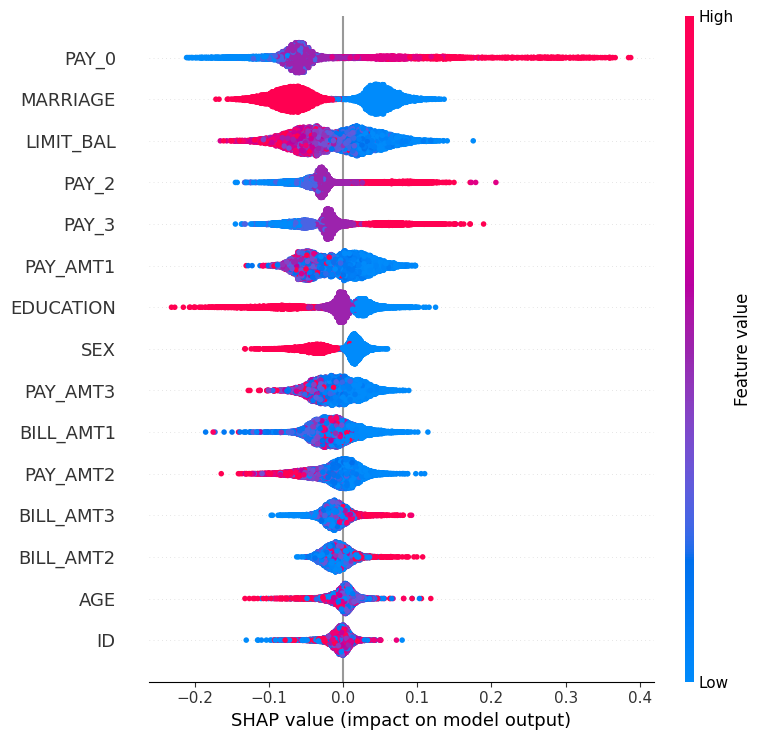

In [ ]:
import shap
# Random Forest SHAP Global Explanation
explainer_shap = shap.TreeExplainer(rf)
shap_values = explainer_shap.shap_values(X_test)

print("SHAP Summary Plot (Positive Class = 1):")
shap.summary_plot(shap_values[:,:,1], X_test)

In [ ]:
# Check if binary classification
print("Number of shap_values outputs:", len(shap_values))

Number of shap_values outputs: 9000


In [ ]:
print("Type of shap_values:", type(shap_values))

Type of shap_values: <class 'numpy.ndarray'>


In [ ]:
print("Shape of shap_values:", np.array(shap_values).shape)

Shape of shap_values: (9000, 15, 2)


SHAP Summary Plot (Positive Class = 1):


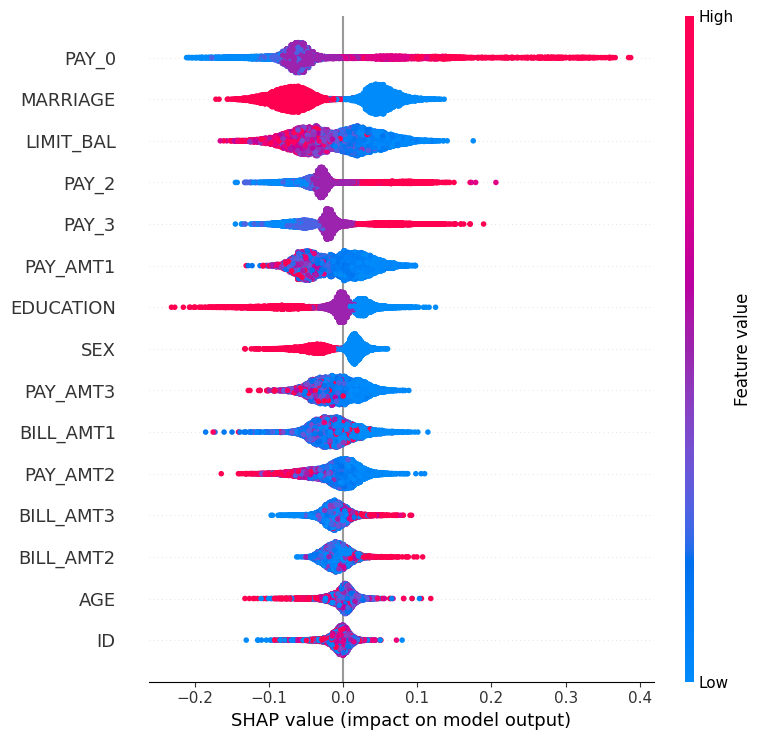

In [ ]:
print("SHAP Summary Plot (Positive Class = 1):")
shap.summary_plot(shap_values[:,:,1], X_test)

# Local Explanations

In [ ]:
positive_idx = y_test[y_test == 1].index[:5]
negative_idx = y_test[y_test == 0].index[:5]

Shap Local Prediction

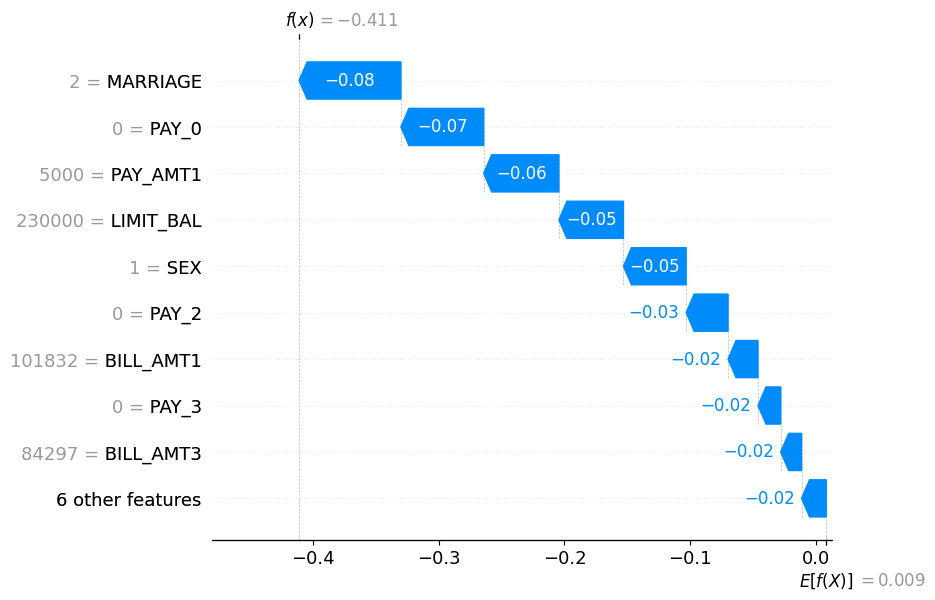

In [ ]:
#Local Prediction For Randomforest
instance_index = 0 # index of the instance to explain
class_index = 1 # index of the target class (1 for positive class)

# Assuming shap_values is a 3D array, extract the values for the instance and class
instance_shap_values = shap_values[instance_index, :, class_index]

# Expected Value is the first element in the SHAP values for the instance
expected_value = shap_values[instance_index, 0, class_index]

shap.plots.waterfall(shap.Explanation(values=instance_shap_values,
                                       base_values=expected_value, # Pass the expected value directly.
                                       data=X_test.iloc[instance_index].values,
                                       feature_names=X_test.columns))

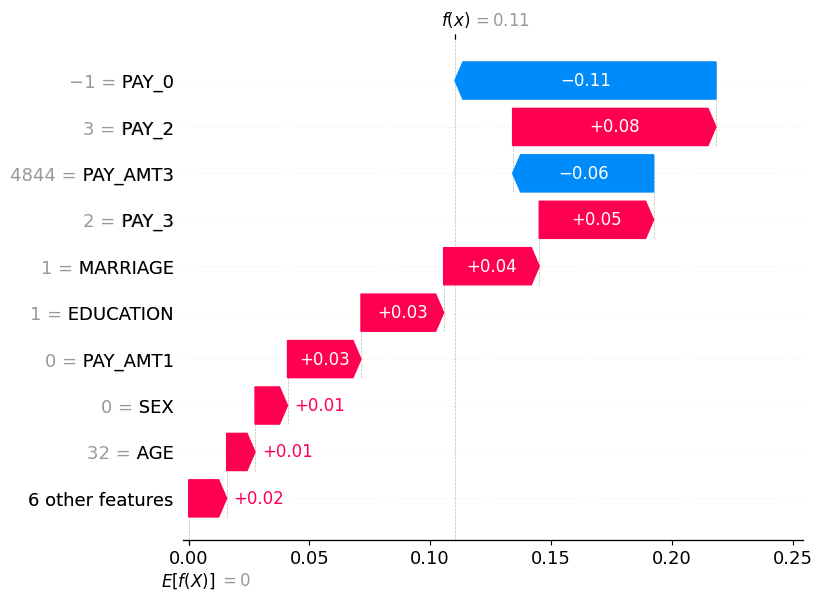

In [ ]:
#Local Prediction For Randomforest
instance_index = 1 # index of the instance to explain
class_index = 1 # index of the target class (1 for positive class)

# Assuming shap_values is a 3D array, extract the values for the instance and class
instance_shap_values = shap_values[instance_index, :, class_index]

# Expected Value is the first element in the SHAP values for the instance
expected_value = shap_values[instance_index, 0, class_index]

shap.plots.waterfall(shap.Explanation(values=instance_shap_values,
                                       base_values=expected_value, # Pass the expected value directly.
                                       data=X_test.iloc[instance_index].values,
                                       feature_names=X_test.columns))

EBM Local Prediction

In [ ]:

# EBM Local
print("EBM Local Explanation for Positive Class (Target=1):")
show(ebm.explain_local(X_test.loc[positive_idx], y_test.loc[positive_idx]))

print("EBM Local Explanation for Negative Class (Target=0):")
show(ebm.explain_local(X_test.loc[negative_idx], y_test.loc[negative_idx]))

EBM Local Explanation for Positive Class (Target=1):


EBM Local Explanation for Negative Class (Target=0):


In [ ]:
import lime
# LIME Local
explainer_lime = lime.lime_tabular.LimeTabularExplainer(
    training_data=np.array(X_train_oversampled),
    feature_names=X_train.columns,
    class_names=['No Default', 'Default'],
    mode='classification'
)

# Positive Example LIME
idx_pos = y_test[y_test == 1].index[0]
exp_pos = explainer_lime.explain_instance(X_test.loc[idx_pos].values, rf.predict_proba)
print("LIME Explanation for a Positive Instance:")
exp_pos.show_in_notebook(show_table=True)

# Negative Example LIME
idx_neg = y_test[y_test == 0].index[0]
exp_neg = explainer_lime.explain_instance(X_test.loc[idx_neg].values, rf.predict_proba)
print("LIME Explanation for a Negative Instance:")
exp_neg.show_in_notebook(show_table=True)

LIME Explanation for a Positive Instance:


/usr/local/lib/python3.11/dist-packages/sklearn/utils/validation.py:2739: UserWarning:

X does not have valid feature names, but RandomForestClassifier was fitted with feature names



LIME Explanation for a Negative Instance:


/usr/local/lib/python3.11/dist-packages/sklearn/utils/validation.py:2739: UserWarning:

X does not have valid feature names, but RandomForestClassifier was fitted with feature names



Anchor And Counterfactual

In [ ]:
!pip install alibi dice-ml

In [ ]:
# Import required libraries
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from alibi.explainers import AnchorTabular
import dice_ml
from dice_ml.utils import helpers

# Load dataset
df = pd.read_csv("/content/UCI_Credit_Card.csv")

In [ ]:
# Rename target
df = df.rename(columns={'default.payment.next.month': 'Target'})

# Encode SEX (1 = male, 2 = female) as binary
df['SEX'] = df['SEX'].map({1: 1, 2: 0})

# One-hot encode EDUCATION and MARRIAGE
df = pd.get_dummies(df, columns=['EDUCATION', 'MARRIAGE'], drop_first=True)

# Define features and target
X = df.drop(columns=["Target"])
y = df["Target"]

# Clean column names
X.columns = X.columns.str.replace(r"[^a-zA-Z0-9_]", "_", regex=True)

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

In [ ]:

# Train model
model = make_pipeline(StandardScaler(), RandomForestClassifier(n_estimators=100, random_state=42))
model.fit(X_train, y_train)

# Predict
y_pred = model.predict(X_test)

# Pick instances
positive_instance = X_test[y_pred == 1].iloc[0]
negative_instance = X_test[y_pred == 0].iloc[0]

# Anchor explanation
explainer = AnchorTabular(predictor=lambda x: model.predict(pd.DataFrame(x, columns=X.columns)),
                          feature_names=X.columns.tolist())
explainer.fit(X_train.values, disc_perc=(25, 50, 75))

# Explain one positive and one negative instance
print("\n🔍 Anchor Explanation for Positive Instance:")
exp_pos = explainer.explain(positive_instance.values, threshold=0.8)
print("Anchor:", exp_pos.anchor)
print("Precision:", exp_pos.precision)
print("Coverage:", exp_pos.coverage)

print("\n🔍 Anchor Explanation for Negative Instance:")
exp_neg = explainer.explain(negative_instance.values, threshold=0.8)
print("Anchor:", exp_neg.anchor)
print("Precision:", exp_neg.precision)
print("Coverage:", exp_neg.coverage)

#


🔍 Anchor Explanation for Positive Instance:
Anchor: ['PAY_0 > 0.00', 'PAY_3 > 0.00', 'PAY_2 > 0.00', 'AGE > 34.00', 'BILL_AMT1 > 3513.75', 'PAY_AMT1 <= 5018.25', 'PAY_AMT3 <= 4580.50', 'EDUCATION_5 <= 0.00', 'EDUCATION_6 <= 0.00', 'PAY_AMT2 <= 5000.00']
Precision: 0.805247225025227
Coverage: 0.0265

🔍 Anchor Explanation for Negative Instance:
Anchor: ['PAY_0 <= -1.00']
Precision: 0.8629629629629629
Coverage: 0.2787


In [ ]:
# First, make sure all features are float (important for DiCE)
X = X.astype(float)

# Combine X and y into one DataFrame for DiCE
full_data = pd.concat([X, y], axis=1)

# List continuous features (basically all features in X)
continuous_features = X.columns.tolist()

# Create DiCE data object
data_dice = dice_ml.Data(
    dataframe=full_data,
    continuous_features=continuous_features,
    outcome_name="Target"
)

# Wrap the model
model_dice = dice_ml.Model(model=model, backend="sklearn")

# Create the DiCE explainer
explainer_dice = dice_ml.Dice(data_dice, model_dice, method="random")

# Generate counterfactuals for a positive instance (predicted 1)
instance_pos = X_test[y_pred == 1].iloc[0:1]
cf_pos = explainer_dice.generate_counterfactuals(instance_pos, total_CFs=3, desired_class="opposite")
print("\n🎯 Counterfactuals for Positive Instance (1 → 0):")
print(cf_pos.cf_examples_list[0].final_cfs_df)

# Generate counterfactuals for a negative instance (predicted 0)
instance_neg = X_test[y_pred == 0].iloc[0:1]
cf_neg = explainer_dice.generate_counterfactuals(instance_neg, total_CFs=3, desired_class="opposite")
print("\n🎯 Counterfactuals for Negative Instance (0 → 1):")
print(cf_neg.cf_examples_list[0].final_cfs_df)


100%|██████████| 1/1 [00:00<00:00,  1.44it/s]



🎯 Counterfactuals for Positive Instance (1 → 0):
      ID  LIMIT_BAL  SEX  AGE  PAY_0  PAY_2  PAY_3  BILL_AMT1  BILL_AMT2  \
0  19078    90000.0    0   40      1      2     -1    40467.0    41495.0   
1  19078    90000.0    0   40      1      2      2    40467.0    41495.0   
2  19078    90000.0    0   40      1      2      2    40467.0    41495.0   

   BILL_AMT3  ...  EDUCATION_1  EDUCATION_2  EDUCATION_3  EDUCATION_4  \
0    42520.0  ...            0            0            1            0   
1    42520.0  ...            0            0            1            0   
2    42520.0  ...            0            0            1            0   

   EDUCATION_5  EDUCATION_6  MARRIAGE_1  MARRIAGE_2  MARRIAGE_3  Target  
0            0            0           0           0           0       0  
1            0            0           1           0           0       0  
2            0            0           1           0           0       0  

[3 rows x 23 columns]


100%|██████████| 1/1 [00:00<00:00,  1.60it/s]


🎯 Counterfactuals for Negative Instance (0 → 1):
     ID  LIMIT_BAL  SEX  AGE  PAY_0  PAY_2  PAY_3  BILL_AMT1  BILL_AMT2  \
0  6908    50000.0    1   46      3     -1     -1     1540.0    26060.0   
1  6908    50000.0    1   46      6     -1     -1     1540.0    26060.0   
2  6908    50000.0    1   46      6     -1     -1     1540.0    26060.0   

   BILL_AMT3  ...  EDUCATION_1  EDUCATION_2  EDUCATION_3  EDUCATION_4  \
0        0.0  ...            0            1            0            0   
1        0.0  ...            0            1            0            0   
2   -61920.6  ...            0            1            0            0   

   EDUCATION_5  EDUCATION_6  MARRIAGE_1  MARRIAGE_2  MARRIAGE_3  Target  
0            0            0           0           1           0       0  
1            0            0           0           1           0       0  
2            0            0           0           1           0       0  

[3 rows x 23 columns]


# Fairness Evaluation


# **Fairness Metrics Evaluation Using Fairlearn**

In [ ]:
!pip install fairlearn


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 240.0/240.0 kB 3.5 MB/s eta 0:00:00


In [ ]:
!pip install aif360
!pip install 'aif360[all]'

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 259.7/259.7 kB 4.5 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 275.7/275.7 kB 5.3 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.6/2.6 MB 35.8 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.7/1.7 MB 54.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 45.8/45.8 kB 2.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 897.5/897.5 kB 43.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 363.4/363.4 MB 3.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.8/13.8 MB 64.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.6/24.6 MB 56.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 883.7/883.7 kB 36.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 664.8/664.8 MB 1.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score
from fairlearn.metrics import (
    MetricFrame,
    selection_rate,
    demographic_parity_difference,
    equalized_odds_difference,
    true_positive_rate,
    false_positive_rate
)


In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score
from fairlearn.metrics import MetricFrame, selection_rate, true_positive_rate, false_positive_rate
from aif360.datasets import BinaryLabelDataset
from aif360.metrics import ClassificationMetric

# Load dataset
data = pd.read_csv('/content/UCI_Credit_Card.csv')  # adjust path as needed
data = data.drop(columns=['ID'], errors='ignore')

# Encode SEX numerically if needed
data['SEX'] = data['SEX'].replace({'Male': 1, 'Female': 0})
data['SEX'] = data['SEX'].replace({2: 0})  # Female = 0, Male = 1

# Define X and y
X = data.drop(columns=['default.payment.next.month'])
y = data['default.payment.next.month']

# Split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# Model training
model = RandomForestClassifier(random_state=42)
model.fit(X_train, y_train)

# Prediction
y_pred = model.predict(X_test)

# Save gender-sensitive attribute for Fairlearn and AIF360
gender_sensitive = X_test['SEX']


/usr/local/lib/python3.11/dist-packages/inFairness/utils/ndcg.py:37: FutureWarning: We've integrated functorch into PyTorch. As the final step of the integration, `functorch.vmap` is deprecated as of PyTorch 2.0 and will be deleted in a future version of PyTorch >= 2.3. Please use `torch.vmap` instead; see the PyTorch 2.0 release notes and/or the `torch.func` migration guide for more details https://pytorch.org/docs/main/func.migrating.html
  vect_normalized_discounted_cumulative_gain = vmap(
/usr/local/lib/python3.11/dist-packages/inFairness/utils/ndcg.py:48: FutureWarning: We've integrated functorch into PyTorch. As the final step of the integration, `functorch.vmap` is deprecated as of PyTorch 2.0 and will be deleted in a future version of PyTorch >= 2.3. Please use `torch.vmap` instead; see the PyTorch 2.0 release notes and/or the `torch.func` migration guide for more details https://pytorch.org/docs/main/func.migrating.html
  monte_carlo_vect_ndcg = vmap(vect_normalized_discounted

In [ ]:
# Metric Frame for Gender
metric_gender = MetricFrame(
    metrics={
        'accuracy': accuracy_score,
        'selection_rate': selection_rate,
        'true_positive_rate': true_positive_rate,
        'false_positive_rate': false_positive_rate,
    },
    y_true=y_test,
    y_pred=y_pred,
    sensitive_features=gender_sensitive
)

print("=== Fairness Metrics by Gender ===")
print(metric_gender.by_group)

print("\nStatistical Parity Difference (Gender):", demographic_parity_difference(y_test, y_pred, sensitive_features=gender_sensitive))
print("Equal Opportunity Difference (Gender):", equalized_odds_difference(y_test, y_pred, sensitive_features=gender_sensitive))


=== Fairness Metrics by Gender ===
     accuracy  selection_rate  true_positive_rate  false_positive_rate
SEX                                                                   
0    0.810690        0.130290            0.367057             0.062739
1    0.815061        0.123754            0.361006             0.056798

Statistical Parity Difference (Gender): 0.006535379470066355
Equal Opportunity Difference (Gender): 0.0060505668791148715


In [ ]:
# Define Age Group for fairness analysis
def age_group(age):
    if age < 30:
        return 'Young'
    elif 30 <= age <= 50:
        return 'Middle-aged'
    else:
        return 'Older'

# Apply the function to X_test['AGE']
age_sensitive = X_test['AGE'].apply(age_group)

# Metric Frame for Age Group
metric_age = MetricFrame(
    metrics={
        'accuracy': accuracy_score,
        'selection_rate': selection_rate,
        'true_positive_rate': true_positive_rate,
        'false_positive_rate': false_positive_rate,
    },
    y_true=y_test,
    y_pred=y_pred,
    sensitive_features=age_sensitive
)

print("\n=== Fairness Metrics by Age Group ===")
print(metric_age.by_group)

print("\nStatistical Parity Difference (Age Group):", demographic_parity_difference(y_test, y_pred, sensitive_features=age_sensitive))
print("Equal Opportunity Difference (Age Group):", equalized_odds_difference(y_test, y_pred, sensitive_features=age_sensitive))



=== Fairness Metrics by Age Group ===
             accuracy  selection_rate  true_positive_rate  false_positive_rate
AGE                                                                           
Middle-aged  0.820722        0.116189            0.348713             0.054932
Older        0.765988        0.190407            0.407407             0.123574
Young        0.804954        0.134159            0.368107             0.063953

Statistical Parity Difference (Age Group): 0.07421826259062453
Equal Opportunity Difference (Age Group): 0.06864193317299402


In [ ]:
# 1. Filter out invalid MARRIAGE = 0
X_test_marriage_clean = X_test[X_test['MARRIAGE'].isin([1, 2, 3])]
y_test_marriage_clean = y_test.loc[X_test_marriage_clean.index]
y_pred_marriage_clean = pd.Series(y_pred, index=X_test.index).loc[X_test_marriage_clean.index]

# 2. Set sensitive feature for cleaned Marriage groups
marriage_sensitive = X_test_marriage_clean['MARRIAGE']

# 3. Import MetricFrame if not already imported
from fairlearn.metrics import MetricFrame, selection_rate, true_positive_rate, false_positive_rate, demographic_parity_difference, equalized_odds_difference
from sklearn.metrics import accuracy_score

# 4. MetricFrame for Marriage (after cleaning)
metric_marriage = MetricFrame(
    metrics={
        'accuracy': accuracy_score,
        'selection_rate': selection_rate,
        'true_positive_rate': true_positive_rate,
        'false_positive_rate': false_positive_rate,
    },
    y_true=y_test_marriage_clean,
    y_pred=y_pred_marriage_clean,
    sensitive_features=marriage_sensitive
)

# 5. Print fairness metrics
print("\n=== Fairness Metrics by Marriage Group (Fairlearn, Cleaned) ===")
print(metric_marriage.by_group)

print("\nStatistical Parity Difference (Marriage):",
      demographic_parity_difference(y_test_marriage_clean, y_pred_marriage_clean, sensitive_features=marriage_sensitive))

print("Equal Opportunity Difference (Marriage):",
      equalized_odds_difference(y_test_marriage_clean, y_pred_marriage_clean, sensitive_features=marriage_sensitive))



=== Fairness Metrics by Marriage Group (Fairlearn, Cleaned) ===
          accuracy  selection_rate  true_positive_rate  false_positive_rate
MARRIAGE                                                                   
1         0.803774        0.132349            0.366397             0.058824
2         0.820858        0.122582            0.363174             0.059899
3         0.793814        0.154639            0.368421             0.102564

Statistical Parity Difference (Marriage): 0.03205717357564618
Equal Opportunity Difference (Marriage): 0.043740573152337855


# **Fairness Metrics Evaluation using AIF 360**

In [ ]:
!pip install aif360
!pip install 'aif360[all]'

In [ ]:
import numpy as np
import pandas as pd
from aif360.datasets import BinaryLabelDataset
from aif360.metrics import BinaryLabelDatasetMetric, ClassificationMetric


In [ ]:
# Step 1: Re-import required libraries (if needed)
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score
from aif360.datasets import BinaryLabelDataset
from aif360.metrics import BinaryLabelDatasetMetric, ClassificationMetric

# Step 2: Load the dataset
data = pd.read_csv('/content/UCI_Credit_Card.csv')  # adjust if using different path
data = data.drop(columns=['ID'], errors='ignore')  # drop ID if exists

# Step 3: Encode 'SEX' numerically for training
data['SEX'] = data['SEX'].replace({'Male': 1, 'Female': 0})  # If you earlier converted SEX to strings
data['SEX'] = data['SEX'].replace({2: 0})  # 1 = Male, 2 = Female → Female = 0

# Step 4: Split features and target
X = data.drop(columns=['default.payment.next.month'])
y = data['default.payment.next.month']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

# Step 5: Train a simple model
model = RandomForestClassifier(random_state=42)
model.fit(X_train, y_train)

# Step 6: Predict
y_pred = model.predict(X_test)

# Step 7: Prepare dataframe for AIF360
df_test = X_test.copy()
df_test['y_true'] = y_test
df_test['y_pred'] = y_pred

# Step 8: Create BinaryLabelDataset for AIF360
test_dataset_true = BinaryLabelDataset(
    df=df_test,
    label_names=['y_true'],
    protected_attribute_names=['SEX'],
    favorable_label=0,  # 0 = No Default
    unfavorable_label=1  # 1 = Default
)

test_dataset_pred = BinaryLabelDataset(
    df=df_test,
    label_names=['y_pred'],
    protected_attribute_names=['SEX'],
    favorable_label=0,
    unfavorable_label=1
)


In [ ]:
from aif360.datasets import BinaryLabelDataset

# 1. Create df_test (true labels)
df_test = X_test.copy()
df_test['y_true'] = y_test.values  # Align properly

# 2. Create df_pred (predicted labels)
df_pred = X_test.copy()
df_pred['y_pred'] = y_pred         # Align properly

test_dataset_true = BinaryLabelDataset(
    df=df_test,
    label_names=['y_true'],
    protected_attribute_names=['SEX'],
    favorable_label=0,
    unfavorable_label=1
)

test_dataset_pred = BinaryLabelDataset(
    df=df_pred,
    label_names=['y_pred'],
    protected_attribute_names=['SEX'],
    favorable_label=0,
    unfavorable_label=1
)


In [ ]:
# Prepare True and Predicted DataFrames for AIF360
df_true = X_test.copy()
df_true['label'] = y_test.values

df_pred = X_test.copy()
df_pred['label'] = y_pred

# Create BinaryLabelDataset objects
from aif360.datasets import BinaryLabelDataset

# Privileged: Male (SEX=1), Unprivileged: Female (SEX=0)
privileged = [{'SEX': 1}]
unprivileged = [{'SEX': 0}]

test_dataset_true = BinaryLabelDataset(
    df=df_true,
    label_names=['label'],
    protected_attribute_names=['SEX'],
    favorable_label=0,
    unfavorable_label=1
)

test_dataset_pred = BinaryLabelDataset(
    df=df_pred,
    label_names=['label'],
    protected_attribute_names=['SEX'],
    favorable_label=0,
    unfavorable_label=1
)


In [ ]:
from aif360.metrics import ClassificationMetric

metric_pred = ClassificationMetric(
    test_dataset_true,
    test_dataset_pred,
    privileged_groups=privileged,
    unprivileged_groups=unprivileged
)

print("=== AIF360 Fairness Metrics (Gender) ===")
print("Disparate Impact:", metric_pred.disparate_impact())
print("Statistical Parity Difference:", metric_pred.statistical_parity_difference())
print("Equal Opportunity Difference:", metric_pred.equal_opportunity_difference())
print("Average Odds Difference:", metric_pred.average_odds_difference())


=== AIF360 Fairness Metrics (Gender) ===
Disparate Impact: 1.0140308724189784
Statistical Parity Difference: 0.012136724332105442
Equal Opportunity Difference: 0.013992563565589755
Average Odds Difference: -0.009370166637063915


In [ ]:
# First, map Age Groups
def age_group(age):
    if age < 30:
        return 'Young'
    elif 30 <= age <= 50:
        return 'Middle-aged'
    else:
        return 'Older'

X_test_age = X_test.copy()
X_test_age['AGE_GROUP'] = X_test_age['AGE'].apply(age_group)

# Focus only on Young and Middle-aged (binary protected attribute)
X_test_age_binary = X_test_age[X_test_age['AGE_GROUP'].isin(['Young', 'Middle-aged'])].copy()
X_test_age_binary['AGE_BIN'] = X_test_age_binary['AGE_GROUP'].map({'Young': 0, 'Middle-aged': 1})


In [ ]:
# Match true and predicted labels
y_test_series = pd.Series(y_test.values, index=X_test.index)
y_pred_series = pd.Series(y_pred, index=X_test.index)

y_test_age = y_test_series.loc[X_test_age_binary.index]
y_pred_age = y_pred_series.loc[X_test_age_binary.index]

# Create true and predicted dataframes
df_age_true = X_test_age_binary.copy()
df_age_true['label'] = y_test_age.values

df_age_pred = X_test_age_binary.copy()
df_age_pred['label'] = y_pred_age.values

# Now drop 'AGE_GROUP' (non-numeric column) for AIF360
df_age_true_numeric = df_age_true.drop(columns=['AGE_GROUP'])
df_age_pred_numeric = df_age_pred.drop(columns=['AGE_GROUP'])



In [ ]:
from aif360.datasets import BinaryLabelDataset

privileged_age = [{'AGE_BIN': 1}]
unprivileged_age = [{'AGE_BIN': 0}]

age_dataset_true = BinaryLabelDataset(
    df=df_age_true_numeric,
    label_names=['label'],
    protected_attribute_names=['AGE_BIN'],
    favorable_label=0,
    unfavorable_label=1
)

age_dataset_pred = BinaryLabelDataset(
    df=df_age_pred_numeric,
    label_names=['label'],
    protected_attribute_names=['AGE_BIN'],
    favorable_label=0,
    unfavorable_label=1
)


In [ ]:
from aif360.metrics import ClassificationMetric

metric_age = ClassificationMetric(
    age_dataset_true,
    age_dataset_pred,
    privileged_groups=privileged_age,
    unprivileged_groups=unprivileged_age
)

print("=== AIF360 Fairness Metrics (Age Group: Middle-aged vs Young) ===")
print("Disparate Impact:", metric_age.disparate_impact())
print("Statistical Parity Difference:", metric_age.statistical_parity_difference())
print("Equal Opportunity Difference:", metric_age.equal_opportunity_difference())
print("Average Odds Difference:", metric_age.average_odds_difference())


=== AIF360 Fairness Metrics (Age Group: Middle-aged vs Young) ===
Disparate Impact: 0.9736014568431096
Statistical Parity Difference: -0.023351057107193984
Equal Opportunity Difference: -0.013975133226131753
Average Odds Difference: -0.028352323052046824


In [ ]:
# First map Age Groups again
X_test_age = X_test.copy()
X_test_age['AGE_GROUP'] = X_test_age['AGE'].apply(age_group)

# Now select only Middle-aged and Older
X_test_age_mid_vs_old = X_test_age[X_test_age['AGE_GROUP'].isin(['Middle-aged', 'Older'])].copy()

# Map: Middle-aged = 1, Older = 0
X_test_age_mid_vs_old['AGE_BIN'] = X_test_age_mid_vs_old['AGE_GROUP'].map({'Middle-aged': 1, 'Older': 0})


In [ ]:
# Match true and predicted labels
y_test_series = pd.Series(y_test.values, index=X_test.index)
y_pred_series = pd.Series(y_pred, index=X_test.index)

y_test_mid_vs_old = y_test_series.loc[X_test_age_mid_vs_old.index]
y_pred_mid_vs_old = y_pred_series.loc[X_test_age_mid_vs_old.index]


In [ ]:
# Create dataframes
df_mid_vs_old_true = X_test_age_mid_vs_old.copy()
df_mid_vs_old_true['label'] = y_test_mid_vs_old.values

df_mid_vs_old_pred = X_test_age_mid_vs_old.copy()
df_mid_vs_old_pred['label'] = y_pred_mid_vs_old.values

# Remove 'AGE_GROUP' (non-numeric)
df_mid_vs_old_true_numeric = df_mid_vs_old_true.drop(columns=['AGE_GROUP'])
df_mid_vs_old_pred_numeric = df_mid_vs_old_pred.drop(columns=['AGE_GROUP'])


In [ ]:
from aif360.datasets import BinaryLabelDataset

# Middle-aged = Privileged (AGE_BIN = 1), Older = Unprivileged (AGE_BIN = 0)
privileged_mid_vs_old = [{'AGE_BIN': 1}]
unprivileged_mid_vs_old = [{'AGE_BIN': 0}]

mid_vs_old_dataset_true = BinaryLabelDataset(
    df=df_mid_vs_old_true_numeric,
    label_names=['label'],
    protected_attribute_names=['AGE_BIN'],
    favorable_label=0,
    unfavorable_label=1
)

mid_vs_old_dataset_pred = BinaryLabelDataset(
    df=df_mid_vs_old_pred_numeric,
    label_names=['label'],
    protected_attribute_names=['AGE_BIN'],
    favorable_label=0,
    unfavorable_label=1
)


In [ ]:
from aif360.metrics import ClassificationMetric

metric_mid_vs_old = ClassificationMetric(
    mid_vs_old_dataset_true,
    mid_vs_old_dataset_pred,
    privileged_groups=privileged_mid_vs_old,
    unprivileged_groups=unprivileged_mid_vs_old
)

# Print fairness metrics
print("=== AIF360 Fairness Metrics (Age Group: Middle-aged vs Older) ===")
print("Disparate Impact:", metric_mid_vs_old.disparate_impact())
print("Statistical Parity Difference:", metric_mid_vs_old.statistical_parity_difference())
print("Equal Opportunity Difference:", metric_mid_vs_old.equal_opportunity_difference())
print("Average Odds Difference:", metric_mid_vs_old.average_odds_difference())


=== AIF360 Fairness Metrics (Age Group: Middle-aged vs Older) ===
Disparate Impact: 0.9313839480627955
Statistical Parity Difference: -0.060694915538838656
Equal Opportunity Difference: -0.03707217170402011
Average Odds Difference: -0.057083974190214826


In [ ]:
# 1. Filter only Married (1) and Single (2)
X_test_married_single = X_test[X_test['MARRIAGE'].isin([1, 2])].copy()

# 2. Map Married = 1 (privileged), Single = 0 (unprivileged)
X_test_married_single['MARRIAGE_BIN'] = X_test_married_single['MARRIAGE'].map({1: 1, 2: 0})

# 3. Align y_test and y_pred with the filtered Marriage data
y_test_series = pd.Series(y_test.values, index=X_test.index)
y_pred_series = pd.Series(y_pred, index=X_test.index)

y_test_married_single = y_test_series.loc[X_test_married_single.index]
y_pred_married_single = y_pred_series.loc[X_test_married_single.index]

# 4. Create true and predicted DataFrames
df_married_true = X_test_married_single.copy()
df_married_true['label'] = y_test_married_single.values

df_married_pred = X_test_married_single.copy()
df_married_pred['label'] = y_pred_married_single.values

# 5. Drop non-numeric columns if necessary
df_married_true = df_married_true.drop(columns=['MARRIAGE'])
df_married_pred = df_married_pred.drop(columns=['MARRIAGE'])

# 6. Create BinaryLabelDataset objects
from aif360.datasets import BinaryLabelDataset
from aif360.metrics import ClassificationMetric

dataset_true = BinaryLabelDataset(
    df=df_married_true,
    label_names=['label'],
    protected_attribute_names=['MARRIAGE_BIN'],
    favorable_label=0,  # 0 = No Default
    unfavorable_label=1  # 1 = Default
)

dataset_pred = BinaryLabelDataset(
    df=df_married_pred,
    label_names=['label'],
    protected_attribute_names=['MARRIAGE_BIN'],
    favorable_label=0,
    unfavorable_label=1
)

# 7. Calculate AIF360 Fairness Metrics
marriage_metric = ClassificationMetric(
    dataset_true,
    dataset_pred,
    privileged_groups=[{'MARRIAGE_BIN': 1}],   # Married
    unprivileged_groups=[{'MARRIAGE_BIN': 0}]  # Single
)

# 8. Display results
print("=== AIF360 Fairness Metrics (Married vs Single) ===")
print("Disparate Impact:", marriage_metric.disparate_impact())
print("Statistical Parity Difference:", marriage_metric.statistical_parity_difference())
print("Equal Opportunity Difference:", marriage_metric.equal_opportunity_difference())
print("Average Odds Difference:", marriage_metric.average_odds_difference())


=== AIF360 Fairness Metrics (Married vs Single) ===
Disparate Impact: 1.011257274692677
Statistical Parity Difference: 0.00976738133267352
Equal Opportunity Difference: -0.0010757549773156017
Average Odds Difference: 0.0010735244413177525
